# 01 · Dados e definição do evento

Antes de qualquer curva de sobrevivência é preciso responder duas perguntas para cada contrato:
**quanto tempo ele foi observado** e **como essa observação terminou** (default, pré-pagamento ou censura).
A base do LendingClub não traz o histórico mensal de pagamentos, só a situação final de cada contrato,
então o tempo é reconstruído a partir das datas de emissão e do último pagamento.

**Fonte:** [LendingClub 2007–2018 (Kaggle)](https://www.kaggle.com/datasets/wordsforthewise/lending-club), arquivo `accepted_2007_to_2018Q4.csv.gz`, com foto tirada em março de 2019.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from time_to_default.data import load_raw
from time_to_default.events import EVENT_LABELS, months_between
from time_to_default.features import OBSERVATION_END, PROCESSED_PATH, SNAPSHOT, build_dataset
from time_to_default.plotting import EVENT_COLORS, GRAY, ORANGE, savefig, set_style
from time_to_default.reporting import update_metrics

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## Carga

O CSV tem 2,26 milhões de linhas e 151 colunas. Ele é lido em blocos, só com as 26 colunas usadas, e salvo em parquet na primeira execução.

In [2]:
raw = load_raw()
print(f"{len(raw):,} contratos, {raw.shape[1]} colunas, {raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB em memória")
raw["loan_status"].value_counts().to_frame("contratos")

2,260,668 contratos, 29 colunas, 231 MB em memória


,contratos
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


## Escopo

| Filtro | Motivo |
|---|---|
| Fora da política de crédito | Contratos de 2007 a 2010 que a própria LendingClub marcou como fora da política vigente. |
| Pedidos conjuntos | `annual_inc` e `dti` são só do titular, mas a aprovação usou a renda do casal (colunas `_joint`). O DTI do titular chega a 999 e não mede o comprometimento real. O produto só existe desde out/2015, com 76% dos contratos ainda em aberto. |
| Moradia ANY/OTHER/NONE | Pouco mais de mil contratos, sem tamanho para análise. |
| Renda zero | O comprometimento de renda não é calculável. |
| Emitidos a partir de nov/2018 | Não têm nenhum mês dentro da janela de observação (ver *fim da observação* abaixo). |

In [3]:
print("DTI por tipo de pedido:")
display(raw.groupby("application_type", observed=True)["dti"].describe(percentiles=[.5, .99])[["count", "50%", "99%", "max"]])

data, funnel = build_dataset(raw)
funnel

DTI por tipo de pedido:


,count,50%,99%,max
application_type,,,,
Individual,"2,139,958.000",17.600,37.580,49.960
Joint App,"118,999.000",24.980,157.000,999.000


,etapa,contratos,removidos
0,base bruta,2260668,0
1,dentro da política de crédito,2257919,2749
2,pedido individual,2137209,120710
3,"moradia própria, financiada ou aluguel",2136024,1185
4,renda anual positiva,2136024,0
5,emitido antes do fim da observação,2064692,71332


## Definição do tempo e do evento

O tempo é contado em **meses desde a emissão**. Como a parcela *k* vence *k* meses depois da emissão, `meses_pagos = last_pymnt_d − issue_d` é o número de parcelas honradas.

| Situação final (`loan_status`) | Evento | Tempo |
|---|---|---|
| Charged Off, Default | **default** | `meses_pagos + 1`: o mês da primeira parcela não paga (1 se nunca pagou) |
| Fully Paid antes do prazo | **pré-pagamento** (risco competitivo) | `meses_pagos` |
| Fully Paid no prazo ou depois | censura | o prazo: o contrato sobreviveu até o fim |
| Current | censura | meses até o fim da observação (nov/2018) |
| Late, In Grace Period | censura | `meses_pagos`: último momento conhecido como saudável |

**Por que o mês da primeira parcela não paga?** É o momento em que o contrato *quebra*, ou seja, quando a cobrança precisa agir. A baixa contábil (charge-off) acontece de 4 a 5 meses depois, e o default regulatório (90 dias) 3 meses depois. As duas são deslocamentos fixos dessa data.

**Por que o pré-pagamento é tratado à parte?** Quem quita antes deixa de correr risco de default. Se ele fosse tratado como censura comum, o Kaplan-Meier suporia que esse contrato *continuaria* sujeito ao default e superestimaria a perda acumulada. O Cox usa o hazard específico do default (pré-pagamento = censura, o que é correto para estimar *efeitos*), e a probabilidade acumulada usa riscos competitivos (Aalen-Johansen).

In [4]:
data["evento"] = data["event"].map(EVENT_LABELS)
pd.crosstab(data["loan_status"], data["evento"], margins=True, margins_name="total")

evento,censurado,default,pré-pagamento,total
loan_status,,,,
Charged Off,6328,255760,0,262088
Current,718519,0,0,718519
Default,32,2,0,34
Fully Paid,287410,0,766974,1054384
In Grace Period,7118,0,0,7118
Late (16-30 days),3654,0,0,3654
Late (31-120 days),18895,0,0,18895
total,1041956,255762,766974,2064692


### Fim da observação: o atraso do charge-off

Um contrato só vira "Charged Off" uns 5 meses depois da primeira parcela não paga. Quem parou de pagar perto da data da foto (mar/2019) ainda aparece como "Late", "In Grace Period" ou até "Current". Contando os charge-offs pelo **mês da primeira parcela não paga**, a série é estável até nov/2018 e despenca depois disso. O problema não é que os tomadores pararam de inadimplir, e sim que esses defaults ainda não foram registrados.

Usar esses meses subestimaria o hazard justamente nas safras recentes, e a censura dos contratos em atraso seria *informativa*: ela tiraria do grupo em risco exatamente quem está para quebrar. Por isso a observação de **todos** os contratos termina em **nov/2018**. Qualquer default, pré-pagamento ou quitação depois dessa data vira censura em nov/2018.

/tmp/ipykernel_489950/694231413.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.axvline(OBSERVATION_END + pd.Timedelta(days=20), color=GRAY, lw=1, ls="--")


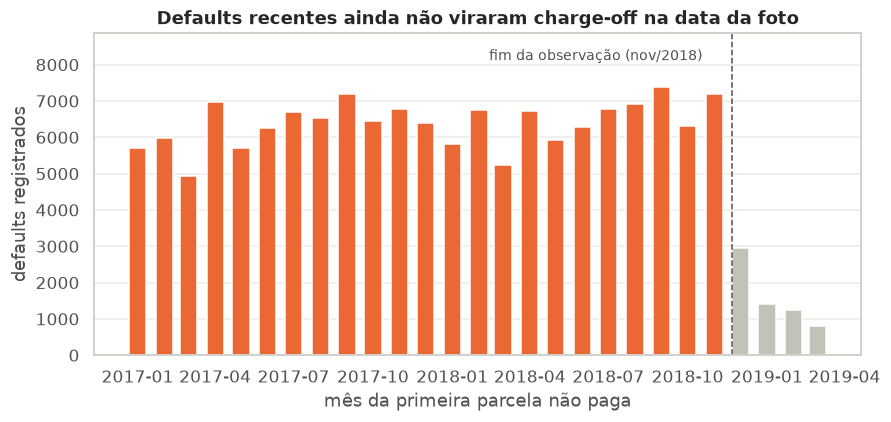

,defaults registrados
mês da 1ª parcela não paga,
2018-07,6780
2018-08,6921
2018-09,7385
2018-10,6301
2018-11,7186
2018-12,2937
2019-01,1405
2019-02,1256
2019-03,816


In [5]:
charged = raw[raw["loan_status"].isin(["Charged Off", "Default"])]
first_miss = (charged["last_pymnt_d"] + pd.offsets.MonthBegin(1)).dt.to_period("M")
monthly = first_miss.value_counts().sort_index().loc["2017-01":"2019-03"]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = monthly.index.to_timestamp()
ax.bar(x, monthly.values, width=20, color=[ORANGE if d < OBSERVATION_END + pd.offsets.MonthBegin(1) else "#c3c2b7" for d in x])
ax.axvline(OBSERVATION_END + pd.Timedelta(days=20), color=GRAY, lw=1, ls="--")
ax.set_ylim(0, monthly.max() * 1.2)
ax.annotate("fim da observação (nov/2018)", (OBSERVATION_END, monthly.max() * 1.1), xytext=(-8, 0),
            textcoords="offset points", ha="right", fontsize=9, color=GRAY)
ax.set_ylabel("defaults registrados")
ax.set_xlabel("mês da primeira parcela não paga")
ax.set_title("Defaults recentes ainda não viraram charge-off na data da foto")
ax.grid(axis="x", visible=False)
savefig(fig, "chargeoff_reporting_lag")
plt.show()
monthly.loc["2018-07":].rename_axis("mês da 1ª parcela não paga").to_frame("defaults registrados")

### Checagens da reconstrução

In [6]:
raw_s = raw[raw["id"].isin(data["id"])]
paid = months_between(raw_s["issue_d"], raw_s["last_pymnt_d"])
term = raw_s["term"].astype(str).str.extract(r"(\d+)")[0].astype(int)
fully = raw_s["loan_status"] == "Fully Paid"
charged = raw_s["loan_status"] == "Charged Off"

checks = pd.Series({
    "último pagamento antes da emissão": int((paid < 0).sum()),
    "default sem nenhum pagamento (tempo = 1)": int((charged & raw_s["last_pymnt_d"].isna()).sum()),
    "default com último pagamento no prazo ou depois (tempo = prazo)": int((charged & (paid >= term)).sum()),
    "quitados depois do prazo (censurados no prazo)": int((fully & (paid > term)).sum()),
    "tempo fora de [1, prazo]": int(((data["duration"] < 1) | (data["duration"] > data["term_months"])).sum()),
}).to_frame("contratos")
checks

,contratos
último pagamento antes da emissão,0
default sem nenhum pagamento (tempo = 1),2178
default com último pagamento no prazo ou depois (tempo = prazo),1050
quitados depois do prazo (censurados no prazo),54161
"tempo fora de [1, prazo]",0


## Eventos por safra

Safras recentes têm pouca observação: a maioria dos contratos de 2017–2018 ainda estava em dia no fim da observação. Essa é exatamente a situação para a qual a análise de sobrevivência existe. Uma taxa de default simples (defaults ÷ contratos) diria que a safra de 2018 é a melhor da história, quando ela só não teve tempo de inadimplir.

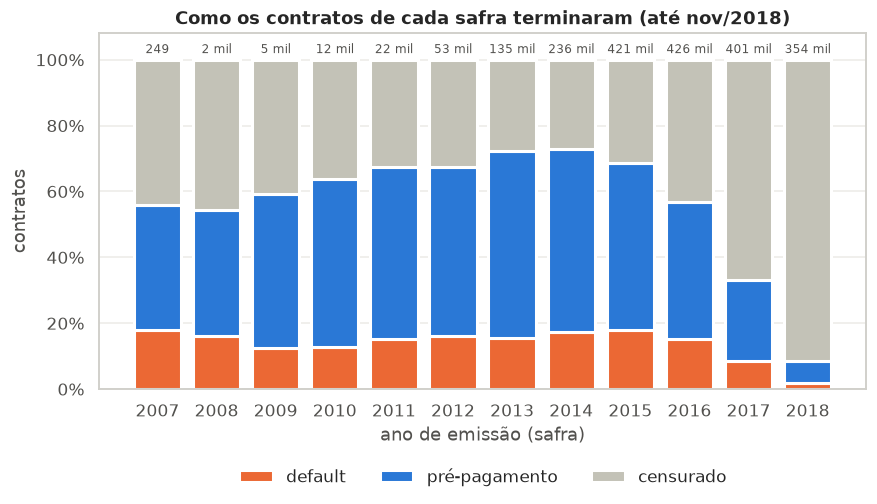

In [7]:
mix = pd.crosstab(data["vintage"], data["evento"], normalize="index")[["default", "pré-pagamento", "censurado"]]
counts = data["vintage"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.2))
bottom = pd.Series(0.0, index=mix.index)
for col in mix.columns:
    ax.bar(mix.index, mix[col], bottom=bottom, color=EVENT_COLORS[col], label=col,
           width=0.8, edgecolor="white", linewidth=2)
    bottom += mix[col]
for x, n in counts.items():
    ax.text(x, 1.02, f"{n / 1000:,.0f} mil" if n >= 1000 else f"{n}", ha="center", fontsize=8, color=GRAY)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 1.08)
ax.set_xticks(mix.index)
ax.set_xlabel("ano de emissão (safra)")
ax.set_ylabel("contratos")
ax.set_title("Como os contratos de cada safra terminaram (até nov/2018)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
ax.grid(axis="x", visible=False)
savefig(fig, "event_mix_by_vintage")
plt.show()

In [8]:
follow = data.groupby("vintage").agg(
    contratos=("id", "size"),
    meses_observados_mediana=("duration", "median"),
    taxa_default_simples=("event", lambda e: (e == 1).mean()),
    censurados=("event", lambda e: (e == 0).mean()),
)
follow

,contratos,meses_observados_mediana,taxa_default_simples,censurados
vintage,,,,
2007,249,32.000,0.181,0.442
2008,1534,34.000,0.160,0.455
2009,4648,31.000,0.125,0.408
2010,11534,33.000,0.129,0.362
2011,21720,32.000,0.152,0.326
2012,53279,30.000,0.162,0.324
2013,134814,28.000,0.156,0.276
2014,235628,27.000,0.174,0.272
2015,420582,27.000,0.178,0.315


## Prazo do contrato

Contratos de 60 meses só passam a existir em 2010 e são concedidos a perfis diferentes (valores maiores e juros mais altos). O prazo vai entrar como **estrato** ou covariável nas próximas etapas, nunca misturado sem controle.

In [9]:
data.groupby("term_months").agg(
    contratos=("id", "size"),
    juros_medio=("int_rate", "mean"),
    valor_medio=("loan_amnt", "mean"),
    default=("event", lambda e: (e == 1).mean()),
    pre_pagamento=("event", lambda e: (e == 2).mean()),
)

,contratos,juros_medio,valor_medio,default,pre_pagamento
term_months,,,,,
36,1486602,11.925,"12,576.954",0.105,0.392
60,578090,15.986,"20,435.549",0.172,0.319


## Salvando a base de sobrevivência

In [10]:
data = data.drop(columns="evento")
data.to_parquet(PROCESSED_PATH, index=False)

update_metrics("data", {
    "raw_loans": int(len(raw)),
    "loans": int(len(data)),
    "snapshot": SNAPSHOT.strftime("%Y-%m"),
    "observation_end": OBSERVATION_END.strftime("%Y-%m"),
    "funnel": funnel.to_dict(orient="records"),
    "event_share": data["event"].map(EVENT_LABELS).value_counts(normalize=True).round(4).to_dict(),
    "term_36_share": round(float((data["term_months"] == 36).mean()), 4),
})
print(f"{len(data):,} contratos salvos em {PROCESSED_PATH.name}")
data["event"].map(EVENT_LABELS).value_counts(normalize=True)

2,064,692 contratos salvos em loans_survival.parquet


event
censurado       0.505
pré-pagamento   0.371
default         0.124
Name: proportion, dtype: float64